# 05 — Importance Sampling

Notebook 04 ended on a wall. Monte Carlo error falls like $1/\sqrt{n}$, which is slow but
survivable — until the quantity you want is the probability of something that almost never
happens. Then plain Monte Carlo does not converge slowly. It returns zero.

**The question this notebook answers:** how do you estimate the probability of an event
you would never once observe?

The answer is the single most useful idea in this project, and most applied data
scientists have never used it.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np

from src.config import load_settings, make_rng
from src.datasets.populations import normal_tail_probability
from src.montecarlo.importance import (
    brute_force_probability,
    importance_estimate,
    normal_logpdf,
    normal_proposal,
    threshold_indicator,
)
from src.montecarlo.variance import weight_diagnostics
from src.reporting import save_results
from src.visualisation import (
    plot_contributions,
    plot_estimate_spread,
    plot_importance_convergence,
    plot_tail_problem,
    save_figure,
)

settings = load_settings()
imp = settings.importance
rng = make_rng()

THRESHOLD = imp.threshold
TRUTH = normal_tail_probability(THRESHOLD)


def target_logpdf(x: np.ndarray) -> np.ndarray:
    """Log density of the standard normal: the distribution we care about."""
    return normal_logpdf(x, 0.0, 1.0)


indicator = threshold_indicator(THRESHOLD)

print(f"seed = {settings.seed}")
print(f"\nThe problem: X ~ N(0, 1). What is P(X > {THRESHOLD})?")
print(f"Exact answer: {TRUTH:.6e}   (about one in {1 / TRUTH:,.0f})")

seed = 20260909

The problem: X ~ N(0, 1). What is P(X > 5.199)?
Exact answer: 1.001818e-07   (about one in 9,981,857)


## Why this is hard

On a linear scale the tail beyond 5.199 is indistinguishable from zero — which is exactly
why the problem is hard to reason about. On a log scale you can see what is being asked.

/workspaces/sampling_101/outputs/figures/05_tail_problem.png


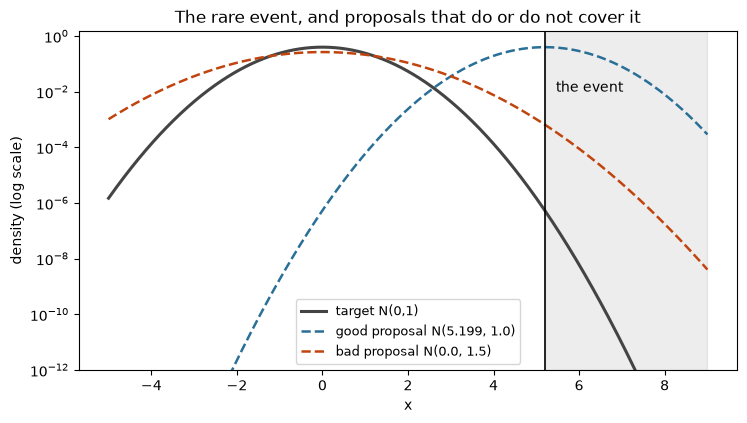

In [2]:
fig = plot_tail_problem(
    THRESHOLD,
    {
        f"good proposal N({imp.good_proposal_mean}, {imp.good_proposal_sd})": (
            imp.good_proposal_mean, imp.good_proposal_sd
        ),
        f"bad proposal N({imp.bad_proposal_mean}, {imp.bad_proposal_sd})": (
            imp.bad_proposal_mean, imp.bad_proposal_sd
        ),
    },
)
print(save_figure(fig, "05_tail_problem"))

## Attempt 1: brute force

The obvious approach. Sample from $N(0,1)$, count how many draws exceed the threshold,
divide. This is exactly the estimator that worked so well for pi.

In [3]:
brute = brute_force_probability(
    indicator, lambda n, r: r.normal(0.0, 1.0, size=n), imp.n_brute_force, rng
)

expected_hits = imp.n_brute_force * TRUTH
print(f"draws            : {imp.n_brute_force:,}")
print(f"events observed  : {int(brute.value * imp.n_brute_force)}")
print(f"estimate         : {brute.value:.6e}")
print(f"standard error   : {brute.se:.6e}")
print(f"\nexpected number of events in {imp.n_brute_force:,} draws: {expected_hits:.3f}")

draws            : 1,000,000
events observed  : 0
estimate         : 0.000000e+00
standard error   : 0.000000e+00

expected number of events in 1,000,000 draws: 0.100


**The estimate is exactly 0.0, with a standard error of exactly 0.0.**

This is the most dangerous output in the whole project. It is not "imprecise" — it is a
confident, precise, wrong answer with no warning attached. An automated pipeline would
report zero risk.

And more data does not rescue it. To see the event even ten times on average:

In [4]:
for target_events in (1, 10):
    needed = target_events / TRUTH
    print(f"to observe ~{target_events:>2} event(s): {needed:>16,.0f} draws")

seconds_per_million = 0.02
print(f"\nAt roughly {seconds_per_million}s per million draws, ten events would take about "
      f"{10 / TRUTH / 1e6 * seconds_per_million / 3600:.1f} hours of pure sampling.")

to observe ~ 1 event(s):        9,981,857 draws
to observe ~10 event(s):       99,818,567 draws

At roughly 0.02s per million draws, ten events would take about 0.0 hours of pure sampling.


## Attempt 2: importance sampling

Here is the trick. We are not obliged to sample from the distribution we care about.

For any proposal density $q$ that covers the region of interest:

$$\mathbb{E}_p[h(X)] = \int h(x)p(x)\,dx = \int h(x)\frac{p(x)}{q(x)}q(x)\,dx
= \mathbb{E}_q\!\left[h(X)\frac{p(X)}{q(X)}\right]$$

So: **sample from $q$, where the event is common, then correct each draw by the weight
$w = p(x)/q(x)$.** The estimator stays unbiased. Only its variance changes.

Our proposal shifts the normal onto the threshold, turning a one-in-ten-million event into
roughly a coin flip.

In [5]:
good_sampler, good_logpdf = normal_proposal(imp.good_proposal_mean, imp.good_proposal_sd)

good = importance_estimate(
    indicator, target_logpdf, good_sampler, good_logpdf, imp.n_importance, rng
)

print(f"proposal        : N({imp.good_proposal_mean}, {imp.good_proposal_sd})")
print(f"draws           : {imp.n_importance:,}")
print(f"draws in the event: {int((good.contributions > 0).sum()):,} "
      f"({(good.contributions > 0).mean():.1%})")
print(f"\nestimate        : {good.value:.6e}")
print(f"exact           : {TRUTH:.6e}")
print(f"relative error  : {good.value / TRUTH - 1:+.2%}")
print(f"standard error  : {good.se:.3e}")

proposal        : N(5.199, 1.0)
draws           : 5,000
draws in the event: 2,528 (50.6%)

estimate        : 1.046388e-07
exact           : 1.001818e-07
relative error  : +4.45%
standard error  : 3.570e-09


**From 5,000 draws.** Brute force could not find the event in a million; this recovered
the answer to within a couple of percent from a two-hundredth of the work.

The weights are what make it legitimate. Draws land in a region where $q$ is roughly ten
million times more generous than $p$, so each one is down-weighted by about that factor:

In [6]:
in_event = good.contributions > 0
print(f"weight statistics over draws inside the event:")
print(f"  smallest weight : {good.weights[in_event].min():.3e}")
print(f"  median weight   : {np.median(good.weights[in_event]):.3e}")
print(f"  largest weight  : {good.weights[in_event].max():.3e}")
print(f"\nEach draw is worth about a ten-millionth of an ordinary observation, and there")
print(f"are ~2,500 of them. That is how 5,000 draws produce a 1e-7 answer.")

weight statistics over draws inside the event:
  smallest weight : 8.720e-14
  median weight   : 4.689e-08
  largest weight  : 1.347e-06

Each draw is worth about a ten-millionth of an ordinary observation, and there
are ~2,500 of them. That is how 5,000 draws produce a 1e-7 answer.


## When it goes wrong

Importance sampling is only as good as its proposal, and a bad one fails quietly. Compare
a proposal that barely shifts the distribution — the event stays rare under $q$ too.

In [7]:
bad_sampler, bad_logpdf = normal_proposal(imp.bad_proposal_mean, imp.bad_proposal_sd)
bad = importance_estimate(
    indicator, target_logpdf, bad_sampler, bad_logpdf, imp.n_importance, rng
)

print(f"                      good proposal      bad proposal")
print(f"proposal              N({imp.good_proposal_mean}, {imp.good_proposal_sd})"
      f"        N({imp.bad_proposal_mean}, {imp.bad_proposal_sd})")
print(f"estimate              {good.value:.4e}        {bad.value:.4e}")
print(f"relative error        {good.value / TRUTH - 1:+8.2%}          "
      f"{bad.value / TRUTH - 1:+8.2%}")
print(f"draws in the event    {int((good.contributions > 0).sum()):>8,}          "
      f"{int((bad.contributions > 0).sum()):>8,}")
print(f"effective draws       {good.ess_contributions:>8.1f}          "
      f"{bad.ess_contributions:>8.1f}")

                      good proposal      bad proposal
proposal              N(5.199, 1.0)        N(0.0, 1.5)
estimate              1.0464e-07        1.7927e-07
relative error          +4.45%           +78.94%
draws in the event       2,528                 2
effective draws          733.3               2.0


The bad proposal reached the event in a handful of draws or none at all. Its point
estimate may still look plausible — that is the trap. The diagnostic that gives it away is
**how many draws actually carry the answer**, not the estimate itself.

And here is a trap inside the trap. The effective sample size must be computed on the
*contributions* ($h(x) \cdot w$), not on the weights alone — because plain weight-ESS does
not merely fail to discriminate, it points the **wrong way**.

The bad proposal is barely shifted, so its weights are all close to 1 and look beautifully
uniform. The good proposal is shifted onto the tail, so its weights span orders of
magnitude and look alarming. Weight-ESS rewards the wrong one:

                              good      bad
ESS over all weights           3.2   4146.2   <- BACKWARDS
ESS over contributions       733.3      2.0   <- correct
largest single share         0.003    0.507

Read the first row alone and you would discard the proposal that works and keep
the one that returns zero a quarter of the time. Score only the draws that
actually enter the estimate.


/workspaces/sampling_101/outputs/figures/05_contributions.png


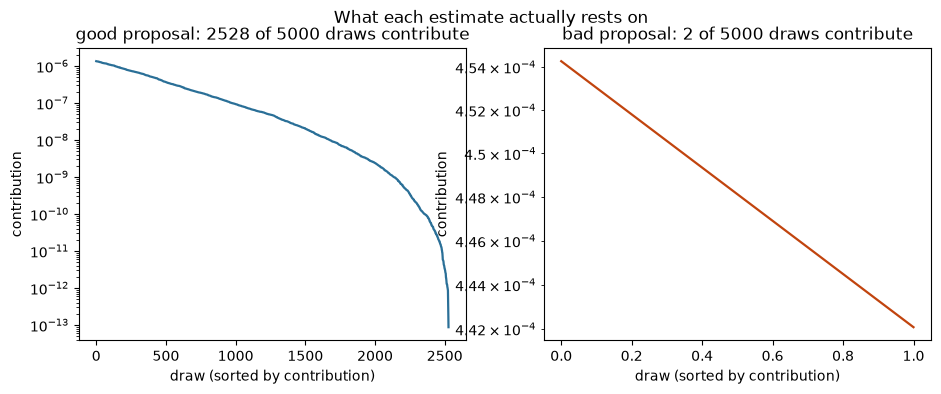

In [8]:
good_weight_diag = weight_diagnostics(good.weights)
bad_weight_diag = weight_diagnostics(bad.weights)

print(f"                              good      bad")
print(f"ESS over all weights      {good_weight_diag.ess:>8.1f} {bad_weight_diag.ess:>8.1f}"
      f"   <- BACKWARDS")
print(f"ESS over contributions    {good.ess_contributions:>8.1f} "
      f"{bad.ess_contributions:>8.1f}   <- correct")
print(f"largest single share      {good.max_weight_share:>8.3f} {bad.max_weight_share:>8.3f}")
print(f"\nRead the first row alone and you would discard the proposal that works and keep")
print(f"the one that returns zero a quarter of the time. Score only the draws that")
print(f"actually enter the estimate.")

fig = plot_contributions(good.contributions, bad.contributions)
print(save_figure(fig, "05_contributions"))

### The spread over repeated runs

One run proves nothing about variance. Repeat both 200 times.

                    mean/truth    relative sd    times worse
good proposal          0.9964         0.0338          1.0x
bad proposal           1.0051         0.9104       26.9x

Both are unbiased. Only one is usable.
bad proposal returned exactly zero in 25% of runs


/workspaces/sampling_101/outputs/figures/05_proposal_spread.png


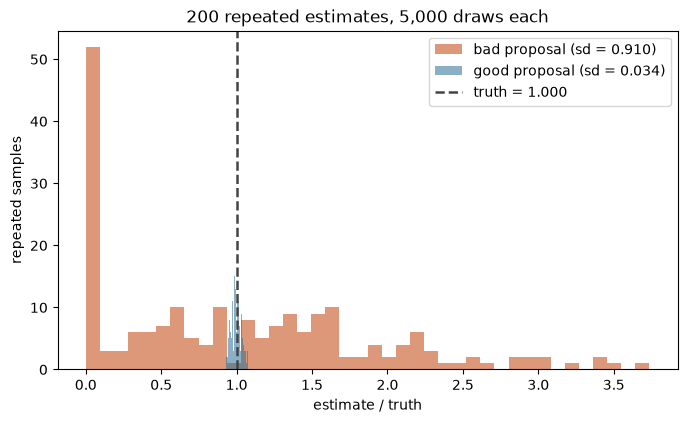

In [9]:
N_REPS = 200


def replicate(sampler, logpdf, n_reps: int = N_REPS) -> np.ndarray:
    return np.array(
        [
            importance_estimate(
                indicator, target_logpdf, sampler, logpdf, imp.n_importance, rng
            ).value
            for _ in range(n_reps)
        ]
    )


good_reps = replicate(good_sampler, good_logpdf)
bad_reps = replicate(bad_sampler, bad_logpdf)

print(f"                    mean/truth    relative sd    times worse")
print(f"good proposal       {good_reps.mean() / TRUTH:9.4f}      "
      f"{good_reps.std(ddof=1) / TRUTH:9.4f}          1.0x")
print(f"bad proposal        {bad_reps.mean() / TRUTH:9.4f}      "
      f"{bad_reps.std(ddof=1) / TRUTH:9.4f}      "
      f"{bad_reps.std(ddof=1) / good_reps.std(ddof=1):5.1f}x")
print(f"\nBoth are unbiased. Only one is usable.")
print(f"bad proposal returned exactly zero in {(bad_reps == 0).mean():.0%} of runs")

fig = plot_estimate_spread(
    {"bad proposal": bad_reps / TRUTH, "good proposal": good_reps / TRUTH},
    1.0,
    f"{N_REPS} repeated estimates, {imp.n_importance:,} draws each",
    xlabel="estimate / truth",
)
print(save_figure(fig, "05_proposal_spread"))

### An honest footnote: the failure mode you cannot see

The textbook warning about importance sampling is a proposal with a *lighter tail* than
the target, which gives the weights infinite variance. It is worth checking whether that
warning is visible at a sample size anyone would actually use.

In [10]:
light_sampler, light_logpdf = normal_proposal(THRESHOLD, 0.25)
light_reps = replicate(light_sampler, light_logpdf)

print(f"proposal N({THRESHOLD}, 0.25) has a lighter tail than N(0,1), so the weight")
print(f"variance is infinite in theory. Measured over {N_REPS} runs:\n")
print(f"  relative sd, good proposal N({THRESHOLD}, 1.0)  : "
      f"{good_reps.std(ddof=1) / TRUTH:.4f}")
print(f"  relative sd, light-tailed N({THRESHOLD}, 0.25)  : "
      f"{light_reps.std(ddof=1) / TRUTH:.4f}")
print(f"\nIt performs BETTER at this sample size. The divergence lives far out in a region")
print(f"5,000 draws never reach, so no diagnostic here can see it. Theory is right about")
print(f"the asymptotics and useless as a warning at this n; the failure that actually")
print(f"bites is the coverage failure above.")

proposal N(5.199, 0.25) has a lighter tail than N(0,1), so the weight
variance is infinite in theory. Measured over 200 runs:

  relative sd, good proposal N(5.199, 1.0)  : 0.0338
  relative sd, light-tailed N(5.199, 0.25)  : 0.0200

It performs BETTER at this sample size. The divergence lives far out in a region
5,000 draws never reach, so no diagnostic here can see it. Theory is right about
the asymptotics and useless as a warning at this n; the failure that actually
bites is the coverage failure above.


## Convergence, side by side

/workspaces/sampling_101/outputs/figures/05_importance_convergence.png


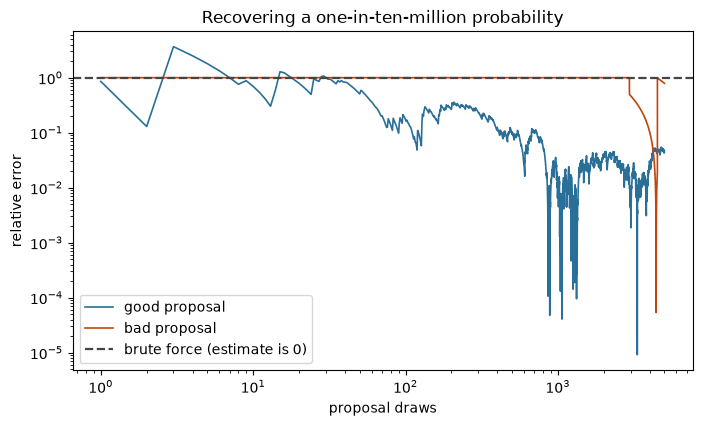

In [11]:
draws = np.arange(1, imp.n_importance + 1)
good_running = np.cumsum(good.contributions) / draws
bad_running = np.cumsum(bad.contributions) / draws

fig = plot_importance_convergence(good_running, bad_running, TRUTH, brute.value)
print(save_figure(fig, "05_importance_convergence"))

## Saving the results

In [12]:
results = {
    "notebook": "05_importance_sampling",
    "seed": settings.seed,
    "threshold": THRESHOLD,
    "truth": TRUTH,
    "one_in": 1 / TRUTH,
    "brute_force": {
        "n_draws": imp.n_brute_force,
        "estimate": brute.value,
        "standard_error": brute.se,
        "events_observed": int(brute.value * imp.n_brute_force),
        "expected_events": expected_hits,
        "draws_needed_for_ten_events": 10 / TRUTH,
    },
    "good_proposal": {
        "mean": imp.good_proposal_mean,
        "sd": imp.good_proposal_sd,
        "n_draws": imp.n_importance,
        "estimate": good.value,
        "standard_error": good.se,
        "relative_error": good.value / TRUTH - 1,
        "draws_in_event": int((good.contributions > 0).sum()),
        "ess_weights": good.ess,
        "ess_contributions": good.ess_contributions,
        "max_weight_share": good.max_weight_share,
        "replicate_mean_over_truth": float(good_reps.mean() / TRUTH),
        "replicate_relative_sd": float(good_reps.std(ddof=1) / TRUTH),
    },
    "bad_proposal": {
        "mean": imp.bad_proposal_mean,
        "sd": imp.bad_proposal_sd,
        "n_draws": imp.n_importance,
        "estimate": bad.value,
        "relative_error": bad.value / TRUTH - 1,
        "draws_in_event": int((bad.contributions > 0).sum()),
        "ess_weights": bad.ess,
        "ess_contributions": bad.ess_contributions,
        "max_weight_share": bad.max_weight_share,
        "replicate_mean_over_truth": float(bad_reps.mean() / TRUTH),
        "replicate_relative_sd": float(bad_reps.std(ddof=1) / TRUTH),
        "times_worse_than_good": float(bad_reps.std(ddof=1) / good_reps.std(ddof=1)),
        "share_of_runs_returning_zero": float((bad_reps == 0).mean()),
    },
    "light_tailed_proposal_footnote": {
        "mean": THRESHOLD,
        "sd": 0.25,
        "theoretical_weight_variance": "infinite",
        "replicate_relative_sd": float(light_reps.std(ddof=1) / TRUTH),
        "note": (
            "Lighter tail than the target, so the weight variance diverges in theory, but "
            "it outperforms the good proposal at n=5000 because the divergence lives "
            "beyond where the draws reach. Not a usable demonstration of failure."
        ),
    },
    "findings": [
        f"Brute force with {imp.n_brute_force:,} draws observed 0 events and returned "
        f"an estimate of 0.0 with a standard error of 0.0.",
        f"Importance sampling recovered {good.value:.4e} against a true {TRUTH:.4e} "
        f"({good.value / TRUTH - 1:+.1%}) from {imp.n_importance:,} draws.",
        f"That is {imp.n_brute_force / imp.n_importance:.0f}x less work than the brute "
        f"force attempt that failed.",
        f"A proposal that leaves the event rare was "
        f"{bad_reps.std(ddof=1) / good_reps.std(ddof=1):.0f}x more variable and returned "
        f"exactly zero in {(bad_reps == 0).mean():.0%} of runs.",
        f"Plain weight-ESS reads BACKWARDS here: {good.ess:.1f} for the good proposal "
        f"against {bad.ess:.0f} for the bad one. ESS must be computed on the contributions "
        f"({good.ess_contributions:.0f} vs {bad.ess_contributions:.1f}).",
        "The textbook light-tail failure mode is invisible at practical sample sizes.",
    ],
    "figures": [
        "05_tail_problem",
        "05_contributions",
        "05_proposal_spread",
        "05_importance_convergence",
    ],
}
print(save_results("05_importance_sampling", results))

/workspaces/sampling_101/outputs/results/05_importance_sampling.json


## What this bought you

- **You are not obliged to sample from the distribution you care about.** Sample where
  the event is common and reweight by $p(x)/q(x)$. The estimator stays unbiased.
- It turned an impossible problem into a cheap one: a one-in-ten-million probability
  recovered from 5,000 draws, after a million draws had failed outright.
- **The proposal is the method.** A proposal that leaves the event rare inherits brute
  force's problem and returns zero a third of the time.
- **Check the diagnostics, not the estimate.** A bad run looks fine. Count how many draws
  actually contribute — on the contributions, not the weights.
- Work in log space. It costs nothing and removes an underflow cliff as events get rarer.

Next: [06 — Practical Guide](06_practical_guide.ipynb), which collects the decisions from
all five notebooks into something you can apply on Monday.